# Manufacturing Downtime – Next-Day Forecast

Runs `scripts/04_forecast.py`, which:
1. Compares three ways of estimating downtime per batch with leave-one-out cross-validation (overall average, product average, regression on product + operator + shift).
2. Uses the method with the lowest error to plan the number of batches for the next day:

`Planned batches = Available minutes / (Min batch time + Expected downtime per batch)`

In [1]:
%run ../scripts/04_forecast.py

Leave-one-out error (mean absolute error, minutes per batch):
                                 Method  MAE_Minutes
                        Overall average        19.06
             Product average (baseline)        20.74
Regression (product + operator + shift)        20.78

Using: Overall average

Forecast for 2024-09-04 (1440 available minutes):
ProductID  Expected_Downtime_Per_Batch  Expected_Cycle_Min  Planned_Batches  Batches_If_No_Downtime
   OR-600                         36.5                96.5               14                      24
   LE-600                         36.5                96.5               14                      24
   CO-600                         36.5                96.5               14                      24
   DC-600                         36.5                96.5               14                      24
   RB-600                         36.5                96.5               14                      24
    CO-2L                         36.5             

## Method comparison (lower error is better)

In [2]:
import pandas as pd
pd.read_csv("../data/forecast/model_comparison.csv")

,Method,MAE_Minutes
0,Overall average,19.06
1,Product average (baseline),20.74
2,Regression (product + operator + shift),20.78


## Next-day plan

In [3]:
pd.read_csv("../data/forecast/next_day_forecast.csv")

,Forecast_Date,ProductID,Flavor,Size,Min_Batch_Time,Expected_Downtime_Per_Batch,Expected_Cycle_Min,Available_Min,Planned_Batches,Batches_If_No_Downtime,Expected_Downtime_Day,Method
0,2024-09-04,OR-600,Orange,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
1,2024-09-04,LE-600,Lemon Lime,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
2,2024-09-04,CO-600,Cola,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
3,2024-09-04,DC-600,Diet Cola,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
4,2024-09-04,RB-600,Root Beer,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
5,2024-09-04,CO-2L,Cola,2 L,98,36.5,134.5,1440,10,14,365,Overall average


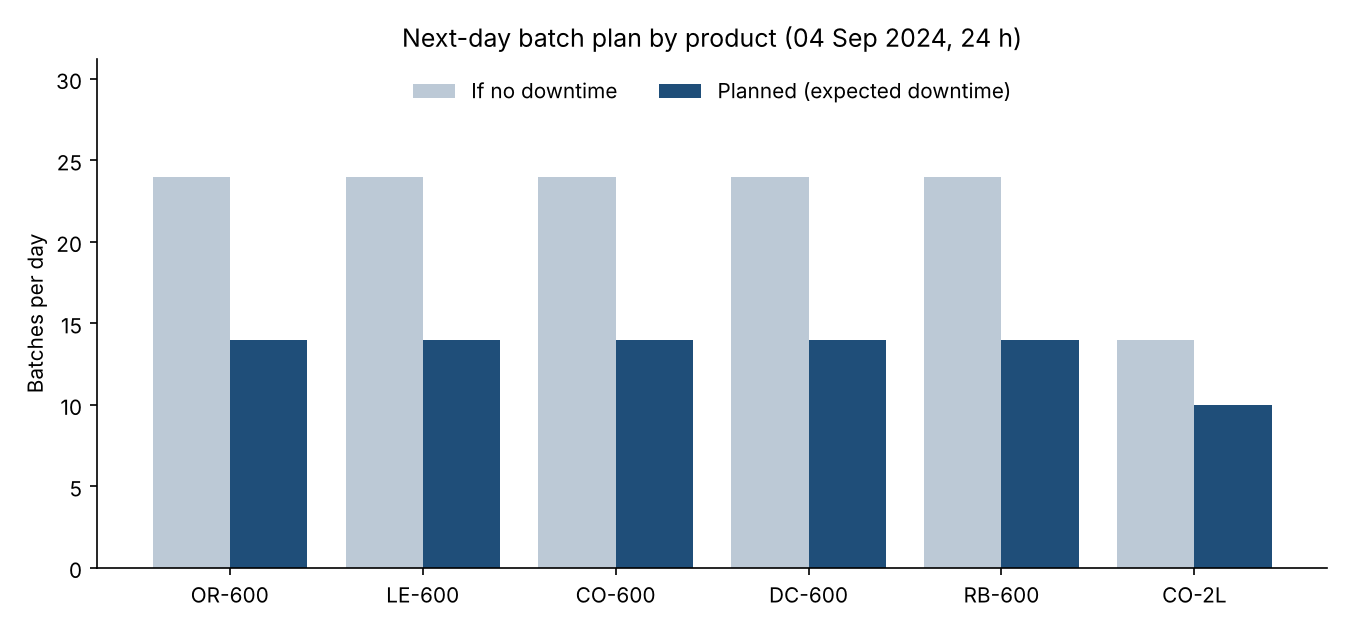

In [4]:
from IPython.display import Image
Image("../reports/figures/06_forecast_batches.png")

## Notes
- With only 38 batches over 5 days, knowing the product, operator or shift does not predict a batch's downtime better than the overall average, so the overall average is used.
- A stronger model needs more history. If required, more data can be generated following the same patterns as the real data and the comparison above re-run.
- `AVAILABLE_MINUTES` in the script is set to 24 hours; change it if the line runs fewer hours.